# CaV1.2 50% masked mutant comparison

    This notebook analyzes the current corrected masked_v3_50pct release with convergence-qualified all_ok_3 tables for WT, G402S, and G406R.

    The analysis is descriptive: global intracellular-gate openness, mutation-local S6-interface contacts, and local Cα-distance changes relative to WT.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "shared").is_dir())
sys.path.insert(0, str(ROOT))
from shared.cav12_coupling_analysis import CAV12_GATE_COLUMNS, gate_openness
from shared.dataset_selection import (
    cav12_active_masked_distance_path, distance_csv_options,
    load_selected_distance_csv,
)

CONDITIONS = ("WT", "G402S", "G406R")
PROTOCOL = "masked_v3_50pct"
SELECTION = "all_ok_3"

def load_condition(condition):
    original = cav12_active_masked_distance_path(ROOT, condition)
    options = distance_csv_options(ROOT, original, "cav12", condition, PROTOCOL)
    source = str(options[SELECTION])
    assert "50pct" in source and "vanilla" not in source.lower(), source
    frame = load_selected_distance_csv(
        f"CaV1.2 {condition} | 50% masked", options, SELECTION,
        fallback_to_all=False,
    ).copy()
    assert frame.attrs["actual_selection"] == SELECTION
    frame["Condition"] = condition
    frame["Protocol"] = PROTOCOL
    return frame, source

datasets, source_paths = {}, {}
for condition in CONDITIONS:
    datasets[condition], source_paths[condition] = load_condition(condition)
assert all("50pct" in p and "vanilla" not in p.lower() for p in source_paths.values())
assert all(column in datasets["WT"].columns for column in CAV12_GATE_COLUMNS)
for condition, path in source_paths.items():
    print(f"{condition}: {path} | n={len(datasets[condition]):,}")

Merged companion distance table: cav12/dataDistances/26-11-10_Cav12_wt_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
CaV1.2 WT | 50% masked: requested=all_ok_3; actual=all_ok_3; path=cav12/dataDistances/26-11-10_Cav12_wt_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv
Merged companion distance table: cav12/dataDistances/26-11-10_Cav12_g402s_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
CaV1.2 G402S | 50% masked: requested=all_ok_3; actual=all_ok_3; path=cav12/dataDistances/26-11-10_Cav12_g402s_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv


Merged companion distance table: cav12/dataDistances/26-11-10_Cav12_g406r_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
CaV1.2 G406R | 50% masked: requested=all_ok_3; actual=all_ok_3; path=cav12/dataDistances/26-11-10_Cav12_g406r_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv
WT: cav12/dataDistances/26-11-10_Cav12_wt_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv | n=4,992
G402S: cav12/dataDistances/26-11-10_Cav12_g402s_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv | n=4,993
G406R: cav12/dataDistances/26-11-10_Cav12_g406r_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv | n=4,998


In [2]:
cohort_rows, gate_rows = [], []
for condition in CONDITIONS:
    frame = datasets[condition]
    parsed = frame["pdb_file"].str.extract(r"seed_(?P<seed>\d+).*?\.r(?P<recycle>\d+)\.pdb$")
    gate_rows.append(pd.DataFrame({
        "Condition": condition, "gate_openness_A": gate_openness(frame),
        "seed": pd.to_numeric(parsed["seed"], errors="coerce"),
        "recycle": pd.to_numeric(parsed["recycle"], errors="coerce"),
    }))
    cohort_rows.append({
        "Condition": condition, "n_models": len(frame),
        "n_seeds": pd.to_numeric(parsed["seed"], errors="coerce").nunique(),
        "n_columns": len(frame.columns), "source_path": source_paths[condition],
        "protocol": PROTOCOL, "selection": SELECTION,
    })
cohort_summary = pd.DataFrame(cohort_rows)
gate_long = pd.concat(gate_rows, ignore_index=True).dropna(subset=["gate_openness_A"])
gate_summary = (
    gate_long.groupby("Condition", sort=False)["gate_openness_A"]
    .agg(n="size", median="median", q025=lambda x: x.quantile(0.025),
         q975=lambda x: x.quantile(0.975)).reset_index()
)
cohort_summary, gate_summary

(  Condition  n_models  n_seeds  n_columns  \
 0        WT      4992      100        697   
 1     G402S      4993      100        697   
 2     G406R      4998      100        697   
 
                                          source_path         protocol  \
 0  cav12/dataDistances/26-11-10_Cav12_wt_masked_v...  masked_v3_50pct   
 1  cav12/dataDistances/26-11-10_Cav12_g402s_maske...  masked_v3_50pct   
 2  cav12/dataDistances/26-11-10_Cav12_g406r_maske...  masked_v3_50pct   
 
   selection  
 0  all_ok_3  
 1  all_ok_3  
 2  all_ok_3  ,
   Condition     n  median      q025   q975
 0        WT  4992  14.405  13.51000  15.80
 1     G402S  4993  14.150  13.10000  15.51
 2     G406R  4998  14.430  13.06925  16.22)

In [3]:
CONTACTS = {
    "G402S": {
        "G402/S402–I1523": ("shortest_GLY402-ILE1523", "shortest_SER402-ILE1523"),
        "G402/S402–M1524": ("shortest_GLY402-MET1524", "shortest_SER402-MET1524"),
    },
    "G406R": {
        "G406/R406–D1528": ("shortest_GLY406-ASP1528", "shortest_ARG406-ASP1528"),
        "G406/R406–D1533": ("shortest_GLY406-ASP1533", "shortest_ARG406-ASP1533"),
    },
}
contact_rows = []
for condition, definitions in CONTACTS.items():
    for contact, (wt_column, mutant_column) in definitions.items():
        for label, column in (("WT", wt_column), (condition, mutant_column)):
            assert column in datasets[label].columns, (label, column)
            values = pd.to_numeric(datasets[label][column], errors="coerce")
            contact_rows.append({
                "Condition": label, "Mutation_context": condition,
                "Contact": contact, "distance_column": column,
                "n_models": values.notna().sum(),
                "median_distance_A": values.median(),
                "contact_fraction_le_4A": (values <= 4.0).mean(),
                "severe_overlap_fraction_lt_2A": (values < 2.0).mean(),
            })
contact_summary = pd.DataFrame(contact_rows)
contact_summary

,Condition,Mutation_context,Contact,distance_column,n_models,median_distance_A,contact_fraction_le_4A,severe_overlap_fraction_lt_2A
0,WT,G402S,G402/S402–I1523,shortest_GLY402-ILE1523,4992,6.0,0.000000,0.0000
1,G402S,G402S,G402/S402–I1523,shortest_SER402-ILE1523,4993,4.1,0.475065,0.0000
2,WT,G402S,G402/S402–M1524,shortest_GLY402-MET1524,4992,3.9,0.570713,0.0000
3,G402S,G402S,G402/S402–M1524,shortest_SER402-MET1524,4993,3.4,0.785299,0.0002
4,WT,G406R,G406/R406–D1528,shortest_GLY406-ASP1528,4992,5.2,0.000601,0.0000
5,G406R,G406R,G406/R406–D1528,shortest_ARG406-ASP1528,4998,4.4,0.184474,0.0006
6,WT,G406R,G406/R406–D1533,shortest_GLY406-ASP1533,4992,8.3,0.000000,0.0000
7,G406R,G406R,G406/R406–D1533,shortest_ARG406-ASP1533,4998,4.8,0.374550,0.0010


In [4]:
LOCAL_FEATURES = [
    "CA_LEU401_CA-ILE1186_CA", "CA_LEU401_CA-VAL753_CA",
    "CA_LEU401_CA-ASP1533_CA", "CA_GLU407_CA-ARG1532_CA",
    "CA_PHE408_CA-THR1531_CA", "CA_LEU401_CA-LEU749_CA",
    "CA_LEU749_CA-VAL1182_CA", "CA_LEU749_CA-ILE1516_CA",
    "CA_VAL1182_CA-ILE1516_CA",
]
LOCAL_FEATURES = [column for column in LOCAL_FEATURES if column in datasets["WT"].columns]
feature_rows = []
for mutant in CONDITIONS[1:]:
    for column in LOCAL_FEATURES:
        wt_values = pd.to_numeric(datasets["WT"][column], errors="coerce")
        mutant_values = pd.to_numeric(datasets[mutant][column], errors="coerce")
        feature_rows.append({
            "Mutant": mutant, "feature": column,
            "WT_median_A": wt_values.median(),
            "mutant_median_A": mutant_values.median(),
            "median_difference_A": mutant_values.median() - wt_values.median(),
            "WT_q025_A": wt_values.quantile(0.025), "WT_q975_A": wt_values.quantile(0.975),
            "mutant_q025_A": mutant_values.quantile(0.025),
            "mutant_q975_A": mutant_values.quantile(0.975),
        })
feature_changes = pd.DataFrame(feature_rows)
feature_changes["absolute_median_difference_A"] = feature_changes["median_difference_A"].abs()
feature_changes = feature_changes.sort_values(
    ["Mutant", "absolute_median_difference_A"], ascending=[True, False]
)
feature_changes

,Mutant,feature,WT_median_A,mutant_median_A,median_difference_A,WT_q025_A,WT_q975_A,mutant_q025_A,mutant_q975_A,absolute_median_difference_A
1,G402S,CA_LEU401_CA-VAL753_CA,11.380,12.76,1.380,11.05000,12.52000,11.83800,13.71,1.380
5,G402S,CA_LEU401_CA-LEU749_CA,8.450,9.50,1.050,8.17775,9.04000,8.67800,9.98,1.050
0,G402S,CA_LEU401_CA-ILE1186_CA,12.400,13.44,1.040,11.80000,13.01000,12.53000,13.96,1.040
2,G402S,CA_LEU401_CA-ASP1533_CA,17.740,18.62,0.880,16.81000,18.27225,17.70800,19.31,0.880
3,G402S,CA_GLU407_CA-ARG1532_CA,9.460,9.92,0.460,8.10000,10.12000,8.57000,10.51,0.460
4,G402S,CA_PHE408_CA-THR1531_CA,12.100,12.48,0.380,10.92000,13.07000,11.35000,12.96,0.380
7,G402S,CA_LEU749_CA-ILE1516_CA,14.405,14.15,-0.255,13.51000,15.80000,13.10000,15.51,0.255
8,G402S,CA_VAL1182_CA-ILE1516_CA,8.990,8.74,-0.250,8.13000,9.84000,8.13000,9.77,0.250
6,G402S,CA_LEU749_CA-VAL1182_CA,8.750,8.66,-0.090,8.18000,9.31000,8.01000,9.58,0.090
13,G406R,CA_PHE408_CA-THR1531_CA,12.100,13.85,1.750,10.92000,13.07000,13.11000,14.62,1.750


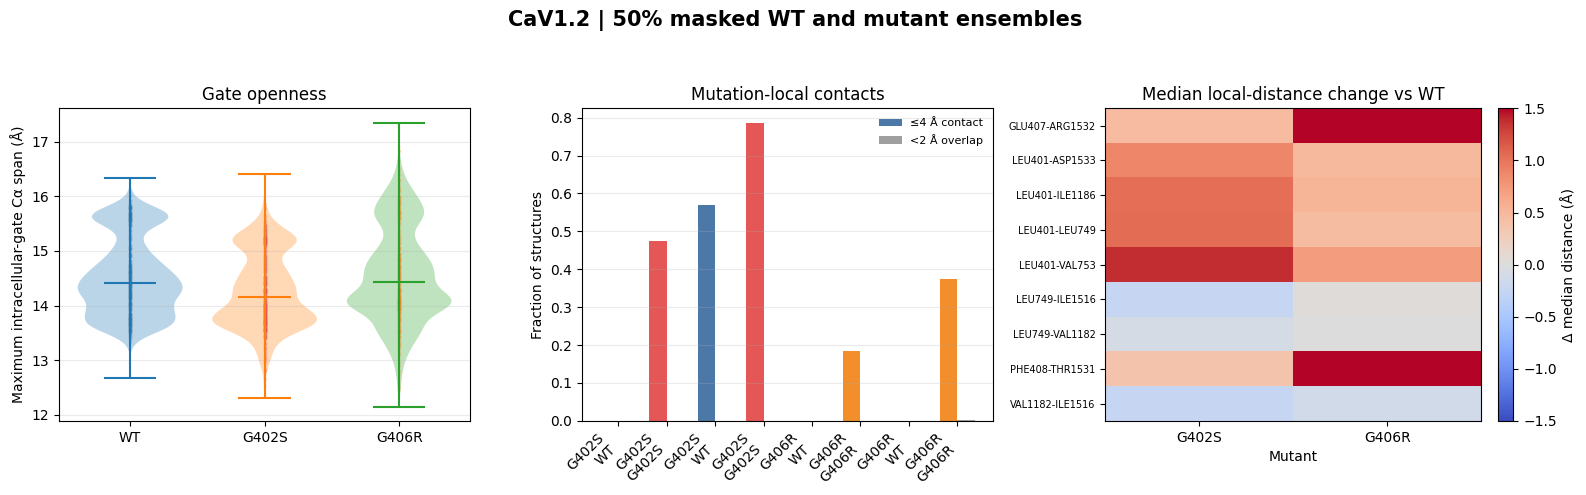

Wrote <repository-root>/docs/figures/cav12_50pct_mutant_comparison/cav12_50pct_gate_contacts_and_local_changes.png


In [5]:
out_fig = ROOT / "docs" / "figures" / "cav12_50pct_mutant_comparison"
out_tab = ROOT / "docs" / "tables" / "cav12_50pct_mutant_comparison"
out_fig.mkdir(parents=True, exist_ok=True)
out_tab.mkdir(parents=True, exist_ok=True)
palette = {"WT": "#4C78A8", "G402S": "#E45756", "G406R": "#F28E2B"}
order = list(CONDITIONS)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, condition in enumerate(order):
    values = gate_long.loc[gate_long.Condition == condition, "gate_openness_A"].to_numpy(float)
    sample = np.random.default_rng(17 + i).choice(values, min(600, len(values)), replace=False)
    axes[0].violinplot(values, positions=[i], showmedians=True, widths=0.78)
    axes[0].scatter(np.full(len(sample), i), sample, s=3, alpha=0.08, color=palette[condition])
axes[0].set_xticks(range(len(order)), order)
axes[0].set_ylabel("Maximum intracellular-gate Cα span (Å)")
axes[0].set_title("Gate openness")
axes[0].grid(axis="y", alpha=0.25)

bar = contact_summary.copy()
bar["label"] = bar["Mutation_context"] + "\n" + bar["Condition"]
x = np.arange(len(bar))
axes[1].bar(x - 0.18, bar["contact_fraction_le_4A"], width=0.36,
            color=[palette[value] for value in bar["Condition"]])
axes[1].bar(x + 0.18, bar["severe_overlap_fraction_lt_2A"], width=0.36,
            color="#777777", alpha=0.7)
axes[1].set_xticks(x, bar["label"], rotation=45, ha="right")
axes[1].set_ylabel("Fraction of structures")
axes[1].set_title("Mutation-local contacts")
axes[1].legend(["≤4 Å contact", "<2 Å overlap"], frameon=False, fontsize=8)
axes[1].grid(axis="y", alpha=0.25)

heat = feature_changes.pivot(index="feature", columns="Mutant", values="median_difference_A")
heat = heat.reindex(columns=list(CONDITIONS[1:])).dropna(how="all")
im = axes[2].imshow(heat.to_numpy(float), aspect="auto", cmap="coolwarm", vmin=-1.5, vmax=1.5)
axes[2].set_yticks(range(len(heat)), [x.replace("CA_", "").replace("_CA", "") for x in heat.index], fontsize=7)
axes[2].set_xticks(range(len(heat.columns)), heat.columns)
axes[2].set_title("Median local-distance change vs WT")
axes[2].set_xlabel("Mutant")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04, label="Δ median distance (Å)")
fig.suptitle("CaV1.2 | 50% masked WT and mutant ensembles", fontsize=15, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(out_fig / "cav12_50pct_gate_contacts_and_local_changes.png", dpi=300, bbox_inches="tight")
plt.show()

cohort_summary.to_csv(out_tab / "cohort_summary.csv", index=False)
gate_summary.to_csv(out_tab / "gate_summary.csv", index=False)
contact_summary.to_csv(out_tab / "mutation_local_contacts.csv", index=False)
feature_changes.to_csv(out_tab / "local_feature_changes_vs_wt.csv", index=False)
gate_long.to_csv(out_tab / "per_structure_gate_openness.csv", index=False)
pd.DataFrame({
    "condition": list(source_paths), "source_path": list(source_paths.values()),
    "protocol": PROTOCOL, "selection": SELECTION,
}).to_csv(out_tab / "source_manifest.csv", index=False)
print(f"Wrote {out_fig / 'cav12_50pct_gate_contacts_and_local_changes.png'}")

## Interpretation boundary

    A contact fraction uses the shortest heavy-atom distance and the stated 4 Å threshold; the <2 Å fraction is reported as a severe-overlap diagnostic. Differences in ensemble medians identify candidate local repacking signatures, not a causal mechanistic effect by themselves.